# Módulo 5 — Detección de Tendencias y Señales Precursoras en Bitácoras
**Pungo Academy · NLP para Mantenimiento Industrial (Nivel Avanzado)**

## Objetivo
Unificar las **3 fuentes textuales de planta** (`3,030 OTs`, `1,586 bitácoras de operador`, `500 reportes de incidentes`) sobre el eje temporal para descubrir:
1. Estacionalidad climática de modos de falla (corrosión en temporada lluviosa)
2. Alertas tempranas por keywords en turnos operativos
3. Scoring automático de urgencia (1–10) en bitácoras con `gpt-4o-mini`
4. Escalación léxica precursora antes de fallas de vibración excesiva
5. Tablero ejecutivo multidisciplinario

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("openai") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openai"])

import json, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Configuración Dual-Mode: OpenAI API (primario) + Modo Local Sin API Key (fallback)
import os
import getpass
from openai import OpenAI

api_key = os.environ.get("OPENAI_API_KEY", "").strip()
if not api_key:
    try:
        api_key = getpass.getpass(
            "Ingresa tu OpenAI API Key (o presiona Enter para Modo Local sin costo): "
        ).strip()
    except Exception:
        api_key = ""

USE_OPENAI = bool(api_key)
client = OpenAI(api_key=api_key) if USE_OPENAI else None
print(
    f"Modo activo: {'OpenAI API Live (gpt-4o-mini + text-embedding-3-small)' if USE_OPENAI else 'Modo Local Determinístico (TF-IDF + Reglas)'}"
)

Modo activo: OpenAI API Live (gpt-4o-mini + text-embedding-3-small)


In [3]:
df_wo = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_work_orders.csv", parse_dates=["fecha_creacion"])
df_logs = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_operator_logs.csv", parse_dates=["fecha_hora"])
df_inc = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_incident_reports.csv", parse_dates=["fecha_evento"])

print(f"Órdenes de trabajo   : {len(df_wo):,}")
print(f"Bitácoras de turno   : {len(df_logs):,}")
print(f"Reportes incidentes  : {len(df_inc):,}")

Órdenes de trabajo   : 3,030
Bitácoras de turno   : 1,586
Reportes incidentes  : 500


## 1. Estacionalidad de Modos de Falla y Patrón de Corrosión

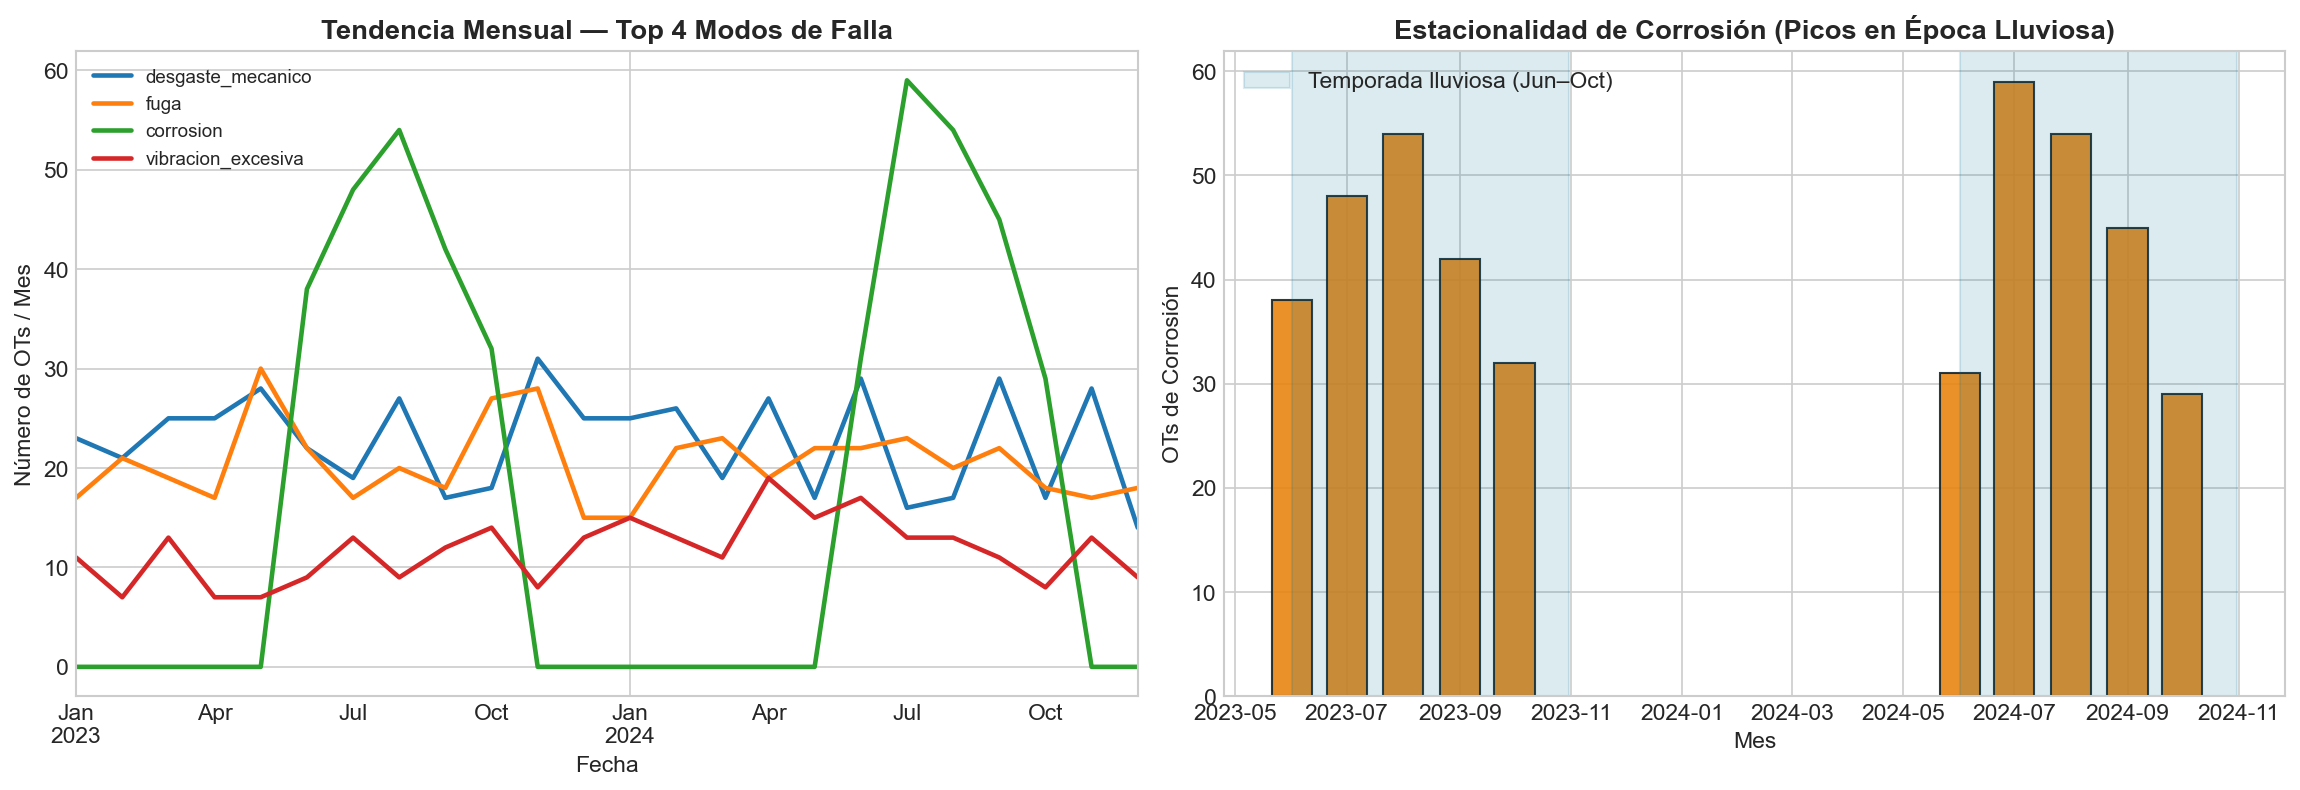

In [4]:
df_wo["mes"] = df_wo["fecha_creacion"].dt.to_period("M").dt.to_timestamp()
monthly_fm = df_wo.groupby(["mes", "modo_falla"]).size().unstack(fill_value=0)
corr_monthly = df_wo[df_wo["modo_falla"] == "corrosion"].groupby("mes").size()

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))
monthly_fm[["desgaste_mecanico", "fuga", "corrosion", "vibracion_excesiva"]].plot(ax=axes[0], linewidth=2.2)
axes[0].set_title("Tendencia Mensual — Top 4 Modos de Falla")
axes[0].set_ylabel("Número de OTs / Mes")
axes[0].set_xlabel("Fecha")
axes[0].legend(fontsize=9)

axes[1].bar(corr_monthly.index, corr_monthly.values, width=22, color=PUNGO_AMBER, edgecolor=PUNGO_NAVY, alpha=0.88)
for year in [2023, 2024]:
    axes[1].axvspan(pd.Timestamp(f"{year}-06-01"), pd.Timestamp(f"{year}-10-31"), alpha=0.14, color=PUNGO_BLUE, label="Temporada lluviosa (Jun–Oct)" if year == 2023 else "")
axes[1].set_title("Estacionalidad de Corrosión (Picos en Época Lluviosa)")
axes[1].set_ylabel("OTs de Corrosión")
axes[1].set_xlabel("Mes")
axes[1].legend()

plt.tight_layout()
plt.show()

## 2. Radar de Alertas en Bitácoras de Cambio de Turno

In [5]:
KEYWORDS_ALERTA = {
    "vibracion": ["vibración", "vibracion", "vibra", "ruido", "golpeteo"],
    "temperatura": ["temperatura", "caliente", "sobrecalentamiento", "temp alta"],
    "fuga": ["fuga", "goteo", "derrame", "charco", "mancha"],
    "presion": ["presión", "presion", "baja presión", "alta presión"],
    "alarma": ["alarma", "disparo", "trip", "paro automático"],
}

def detectar_alertas(texto: str) -> list[str]:
    if pd.isna(texto):
        return []
    tl = str(texto).lower()
    return [cat for cat, kws in KEYWORDS_ALERTA.items() if any(kw in tl for kw in kws)]

df_logs["alertas"] = df_logs["entrada"].apply(detectar_alertas)
df_logs["tiene_alerta"] = df_logs["alertas"].apply(len) > 0
print(f"Bitácoras con señal de alerta: {df_logs['tiene_alerta'].sum():,} ({df_logs['tiene_alerta'].mean():.1%})")

all_alertas = [a for al in df_logs["alertas"] for a in al]
for cat, cnt in Counter(all_alertas).most_common():
    print(f"  {cat:14s}: {cnt:4d}")

Bitácoras con señal de alerta: 872 (55.0%)
  presion       :  336
  temperatura   :  321
  alarma        :  207
  vibracion     :  204
  fuga          :  148


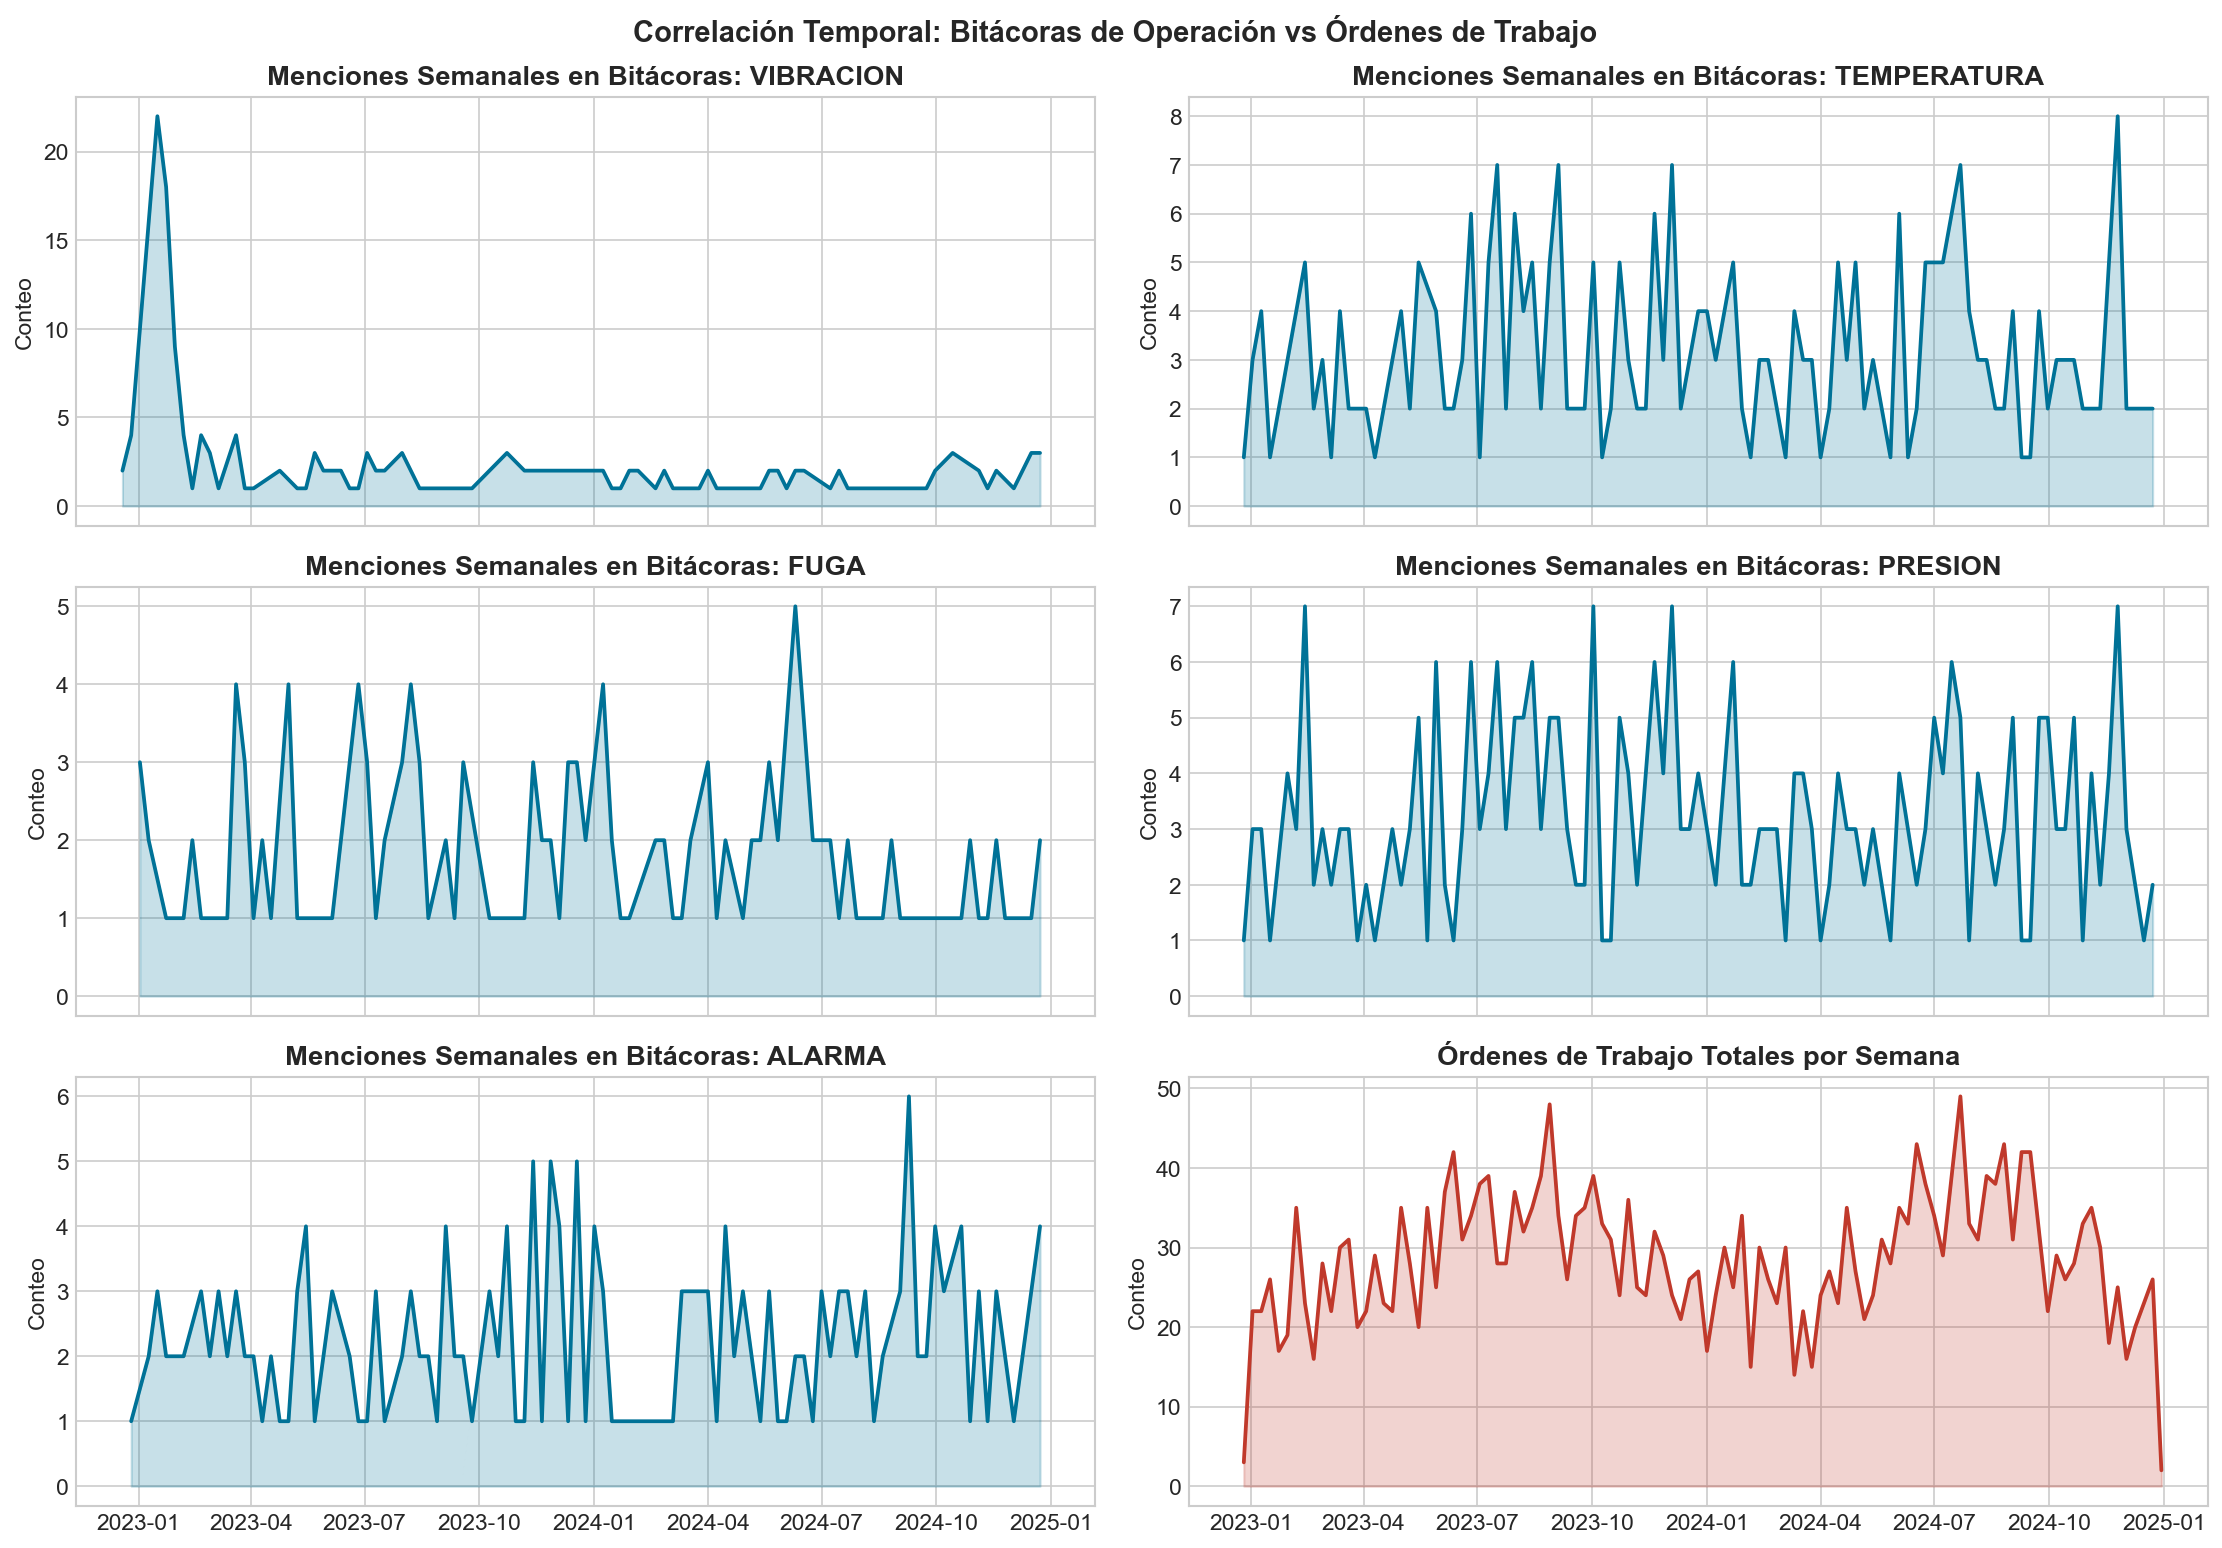

In [6]:
df_logs["semana"] = df_logs["fecha_hora"].dt.to_period("W").dt.to_timestamp()
df_wo["semana"] = df_wo["fecha_creacion"].dt.to_period("W").dt.to_timestamp()

fig, axes = plt.subplots(3, 2, figsize=(15, 10.5), sharex=True)
axes = axes.flatten()
for idx, cat in enumerate(KEYWORDS_ALERTA):
    mask = df_logs["alertas"].apply(lambda x: cat in x)
    ser = df_logs[mask].groupby("semana").size()
    axes[idx].plot(ser.index, ser.values, color=PUNGO_BLUE, linewidth=1.8)
    axes[idx].fill_between(ser.index, ser.values, alpha=0.22, color=PUNGO_BLUE)
    axes[idx].set_title(f"Menciones Semanales en Bitácoras: {cat.upper()}")
    axes[idx].set_ylabel("Conteo")

ots_w = df_wo.groupby("semana").size()
axes[5].plot(ots_w.index, ots_w.values, color=PUNGO_RED, linewidth=1.8)
axes[5].fill_between(ots_w.index, ots_w.values, alpha=0.22, color=PUNGO_RED)
axes[5].set_title("Órdenes de Trabajo Totales por Semana")
axes[5].set_ylabel("Conteo")

plt.suptitle("Correlación Temporal: Bitácoras de Operación vs Órdenes de Trabajo", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Scoring de Urgencia (1–10) con `gpt-4o-mini`
Convertimos texto libre de bitácoras en un **indicador cuantitativo de riesgo operativo** de 1 a 10 para priorizar entregas de turno.

In [7]:
PROMPT_URGENCIA = """Eres supervisor de operaciones petroleras. Evalúa la urgencia de esta entrada de bitácora de 1 a 10:
1-2: Rutina normal | 3-4: Observación menor | 5-6: Requiere monitoreo/notificación | 7-8: Intervención prioritaria | 9-10: Emergencia / paro / riesgo HSE.
Responde SOLO con JSON válido: {"score": <int 1..10>, "razon": "<breve explicación>"}."""

def score_urgencia(texto: str) -> dict:
    if USE_OPENAI:
        try:
            resp = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": PROMPT_URGENCIA},
                    {"role": "user", "content": str(texto)},
                ],
                temperature=0,
                response_format={"type": "json_object"},
            )
            return json.loads(resp.choices[0].message.content)
        except Exception as exc:
            print(f"Fallback urgencia: {exc}")
    tl = str(texto).lower()
    if any(k in tl for k in ["emergencia", "derrame", "crítica", "paro", "trip", "alarma"]):
        return {"score": 9, "razon": "Evento crítico o disparo de protección detectado."}
    if any(k in tl for k in ["severa", "preocupante", "fuga", "alta vibración"]):
        return {"score": 7, "razon": "Anomalía activa que requiere intervención."}
    if any(k in tl for k in ["leve", "notable", "monitoreo", "observa"]):
        return {"score": 4, "razon": "Desviación incipiente bajo vigilancia."}
    return {"score": 2, "razon": "Condición operativa rutinaria."}

sample_logs = df_logs.sample(30, random_state=42).copy()
scores = []
for _, row in sample_logs.iterrows():
    scores.append(score_urgencia(row["entrada"]))
    if USE_OPENAI:
        time.sleep(0.04)

sample_logs["urgencia_score"] = [int(s.get("score", 5)) for s in scores]
sample_logs["urgencia_razon"] = [s.get("razon", "") for s in scores]

print("TOP 5 ENTRADAS DE MAYOR URGENCIA")
for _, r in sample_logs.nlargest(5, "urgencia_score").iterrows():
    print(f"  [{r['urgencia_score']}/10 | {r['tipo_entrada']}] {r['entrada'][:90]}... -> {r['urgencia_razon']}")

TOP 5 ENTRADAS DE MAYOR URGENCIA
  [8/10 | anomalia] Se observa vibración severa en M-201. Se recomienda intervención de mantenimiento.... -> La vibración severa puede indicar un problema mecánico que podría afectar la operación y la seguridad del equipo, por lo que se requiere una intervención prioritaria.
  [7/10 | anomalia] Se observa vibración preocupante en LT-1504. Se recomienda intervención de mantenimiento.... -> La vibración preocupante indica un posible fallo mecánico que podría afectar la operación, por lo que se requiere intervención prioritaria para evitar daños mayores.
  [6/10 | anomalia] P-102 con vibración inusual. Se incrementa frecuencia de monitoreo a cada 2 horas.... -> La vibración inusual en P-102 requiere monitoreo más frecuente, lo que indica un posible problema que podría escalar si no se atiende.
  [6/10 | anomalia] Se observa temperatura elevada en Bomba dosificadora de químicos. Se notifica a mantenimie... -> La temperatura elevada en la bomba dosificadora 

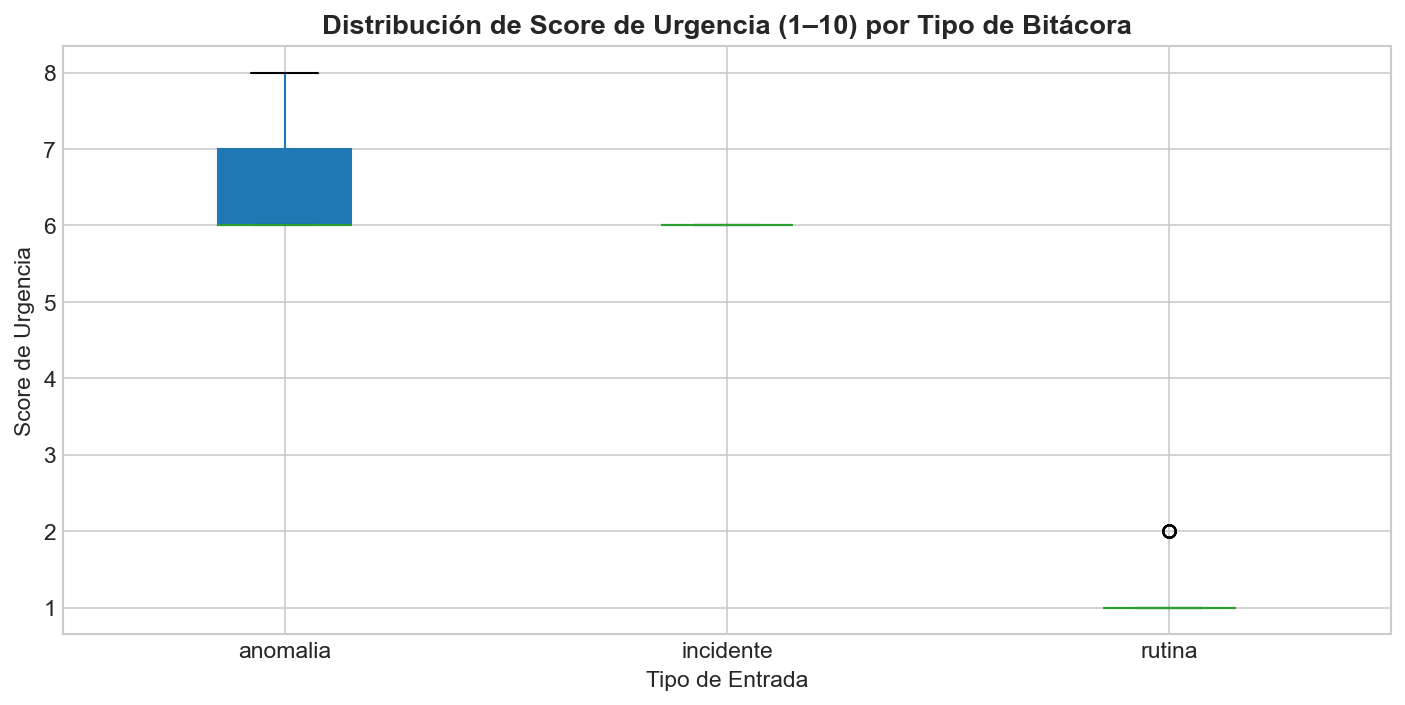

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 5))
sample_logs.boxplot(column="urgencia_score", by="tipo_entrada", ax=ax, patch_artist=True)
ax.set_title("Distribución de Score de Urgencia (1–10) por Tipo de Bitácora")
ax.set_xlabel("Tipo de Entrada")
ax.set_ylabel("Score de Urgencia")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 4. Detección de Escalación Léxica Precursora de Falla
Analizamos cómo los adjetivos en las notas de vibración escalan progresivamente (`leve → moderada → preocupante → severa → crítica`) antes de la falla mecánica.

Entradas con mención de vibración: 143


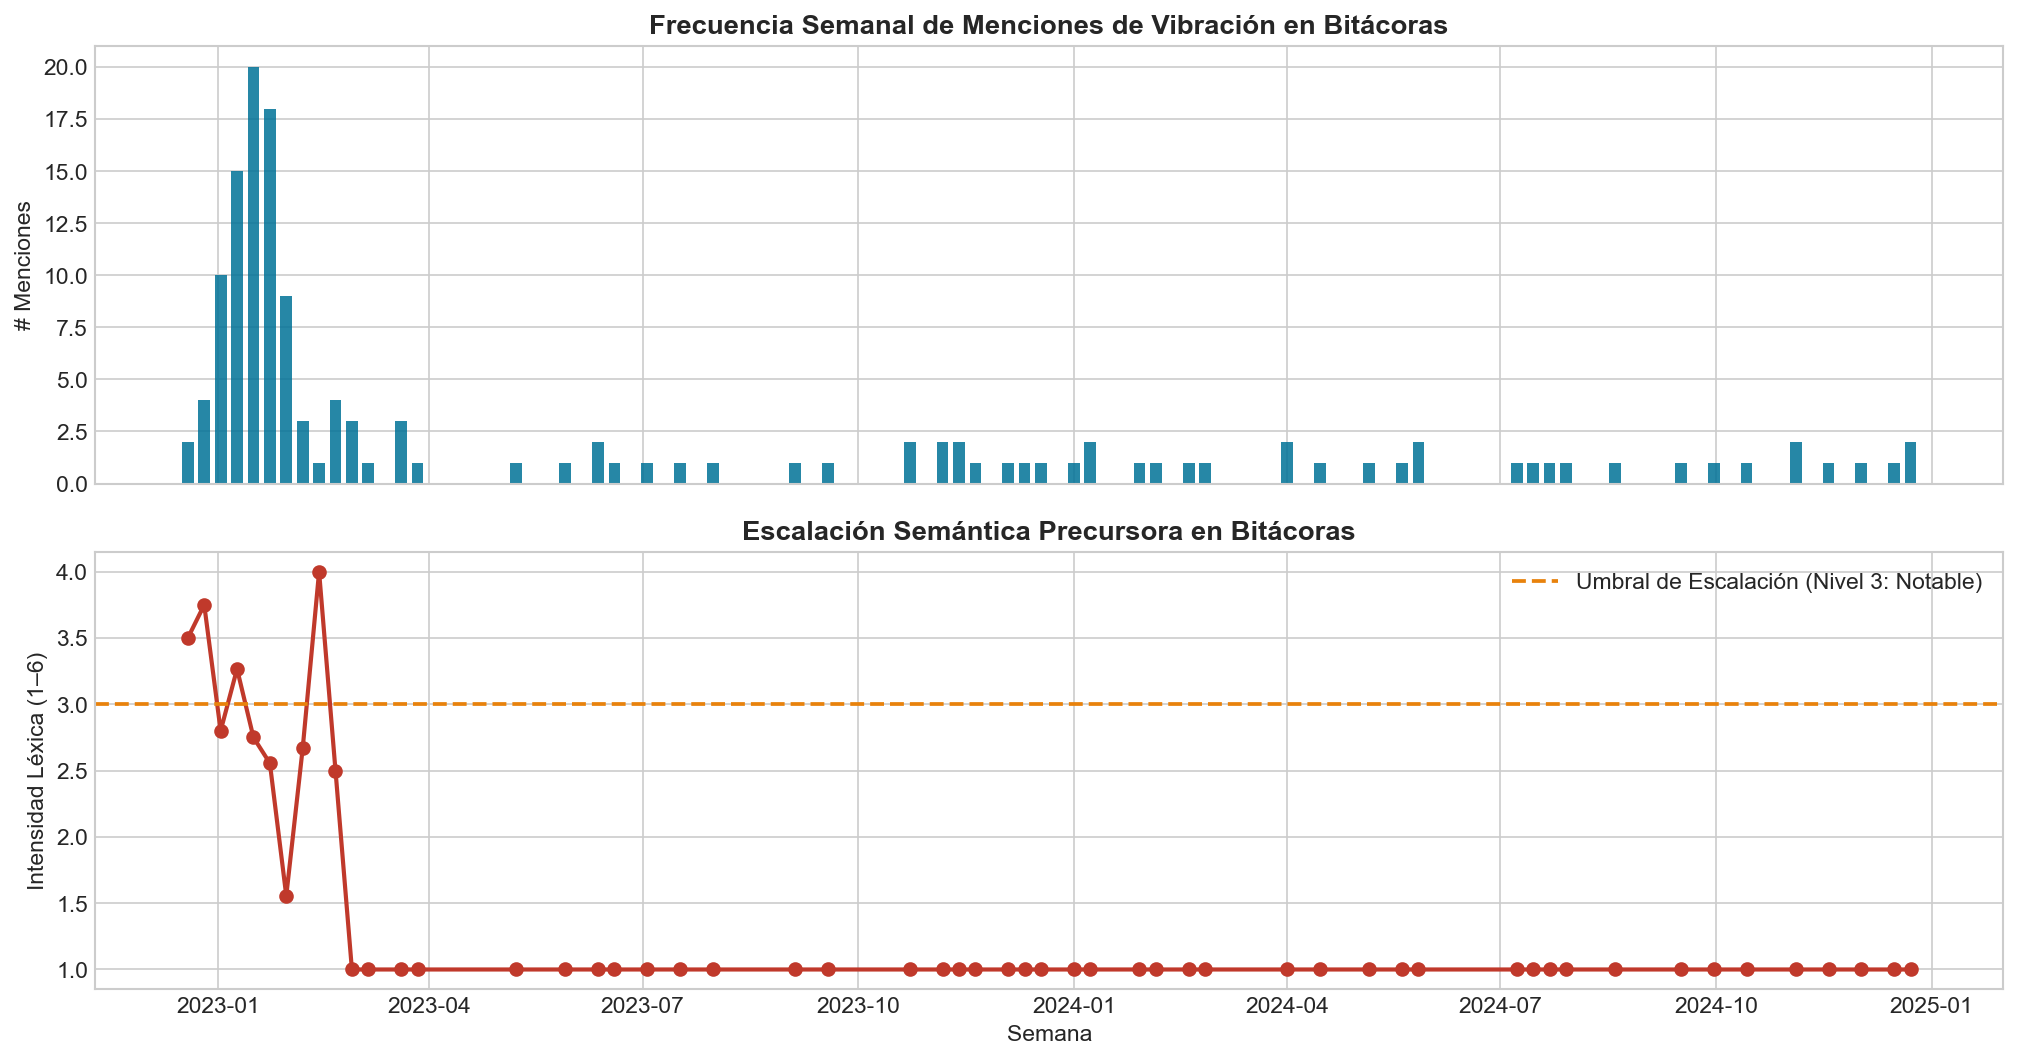

In [9]:
df_logs["menciona_vibracion"] = df_logs["entrada"].str.lower().str.contains("vibración|vibracion|vibra", na=False)
URGENCY_WORDS = {"leve": 1, "moderada": 2, "notable": 3, "preocupante": 4, "severa": 5, "crítica": 6}

def urgencia_vibracion(texto: str) -> int:
    if pd.isna(texto):
        return 0
    tl = str(texto).lower()
    for word, score in URGENCY_WORDS.items():
        if word in tl:
            return score
    return 1 if ("vibración" in tl or "vibracion" in tl) else 0

df_logs["urgencia_vibr"] = df_logs["entrada"].apply(urgencia_vibracion)
vibr_logs = df_logs[df_logs["menciona_vibracion"]].copy()
vibr_logs["semana"] = vibr_logs["fecha_hora"].dt.to_period("W").dt.to_timestamp()
print(f"Entradas con mención de vibración: {len(vibr_logs)}")

fig, axes = plt.subplots(2, 1, figsize=(13.5, 7.2), sharex=True)
conteo_sem = vibr_logs.groupby("semana").size()
urg_sem = vibr_logs.groupby("semana")["urgencia_vibr"].mean()

axes[0].bar(conteo_sem.index, conteo_sem.values, width=5, color=PUNGO_BLUE, alpha=0.85)
axes[0].set_ylabel("# Menciones")
axes[0].set_title("Frecuencia Semanal de Menciones de Vibración en Bitácoras")

axes[1].plot(urg_sem.index, urg_sem.values, "o-", color=PUNGO_RED, linewidth=2)
axes[1].axhline(3.0, color=PUNGO_AMBER, linestyle="--", linewidth=1.8, label="Umbral de Escalación (Nivel 3: Notable)")
axes[1].set_ylabel("Intensidad Léxica (1–6)")
axes[1].set_xlabel("Semana")
axes[1].set_title("Escalación Semántica Precursora en Bitácoras")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Tablero Ejecutivo Multi-Fuente

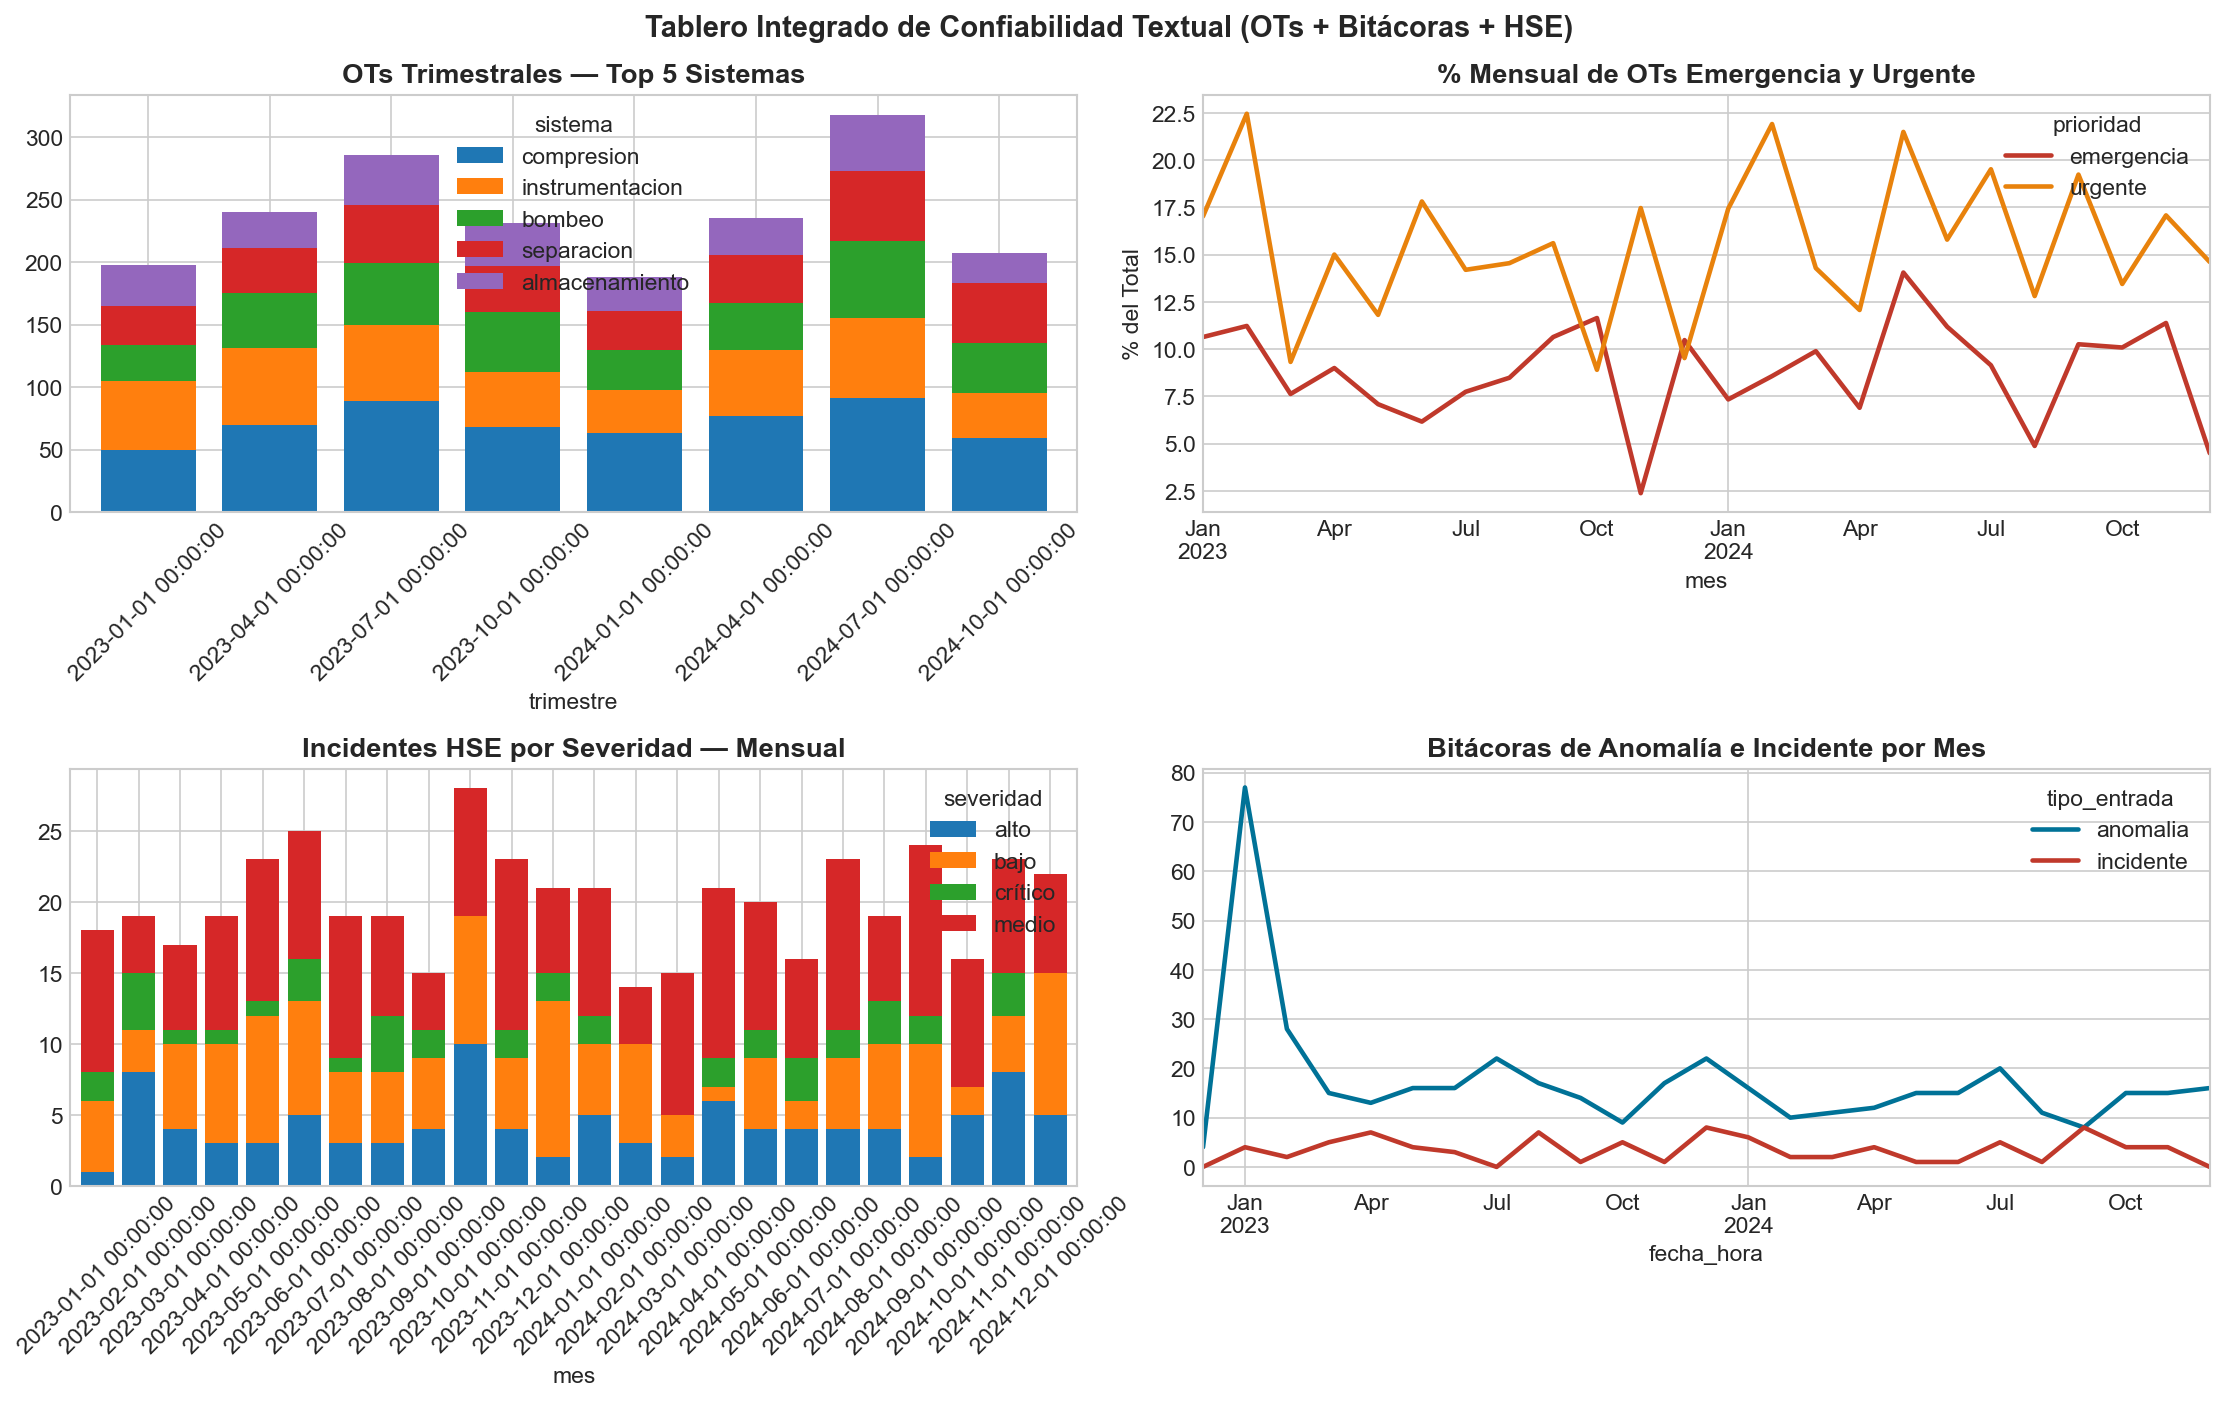

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

df_wo["trimestre"] = df_wo["fecha_creacion"].dt.to_period("Q").dt.to_timestamp()
top_sis = df_wo["sistema"].value_counts().head(5).index
df_wo.groupby(["trimestre", "sistema"]).size().unstack(fill_value=0)[top_sis].plot(kind="bar", stacked=True, ax=axes[0, 0], width=0.78)
axes[0, 0].set_title("OTs Trimestrales — Top 5 Sistemas")
axes[0, 0].tick_params(axis="x", rotation=45)

prio_m = df_wo.groupby(["mes", "prioridad"]).size().unstack(fill_value=0)
prio_pct = prio_m.div(prio_m.sum(axis=1), axis=0) * 100
prio_pct[["emergencia", "urgente"]].plot(ax=axes[0, 1], linewidth=2.2, color=[PUNGO_RED, PUNGO_AMBER])
axes[0, 1].set_title("% Mensual de OTs Emergencia y Urgente")
axes[0, 1].set_ylabel("% del Total")

df_inc["mes"] = df_inc["fecha_evento"].dt.to_period("M").dt.to_timestamp()
df_inc.groupby(["mes", "severidad"]).size().unstack(fill_value=0).plot(kind="bar", stacked=True, ax=axes[1, 0], width=0.8)
axes[1, 0].set_title("Incidentes HSE por Severidad — Mensual")
axes[1, 0].tick_params(axis="x", rotation=45)

log_tm = df_logs.groupby([df_logs["fecha_hora"].dt.to_period("M").dt.to_timestamp(), "tipo_entrada"]).size().unstack(fill_value=0)
log_tm[["anomalia", "incidente"]].plot(ax=axes[1, 1], linewidth=2.2, color=[PUNGO_BLUE, PUNGO_RED])
axes[1, 1].set_title("Bitácoras de Anomalía e Incidente por Mes")

plt.suptitle("Tablero Integrado de Confiabilidad Textual (OTs + Bitácoras + HSE)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Conclusiones del Módulo 5
1. La **corrosión presenta estacionalidad clara** durante los meses lluviosos (Jun–Oct), permitiendo programar inspecciones UT preventivas.
2. El monitoreo continuo de adjetivos de intensidad en bitácoras detecta la **escalación de fallas mecánicas antes del disparo por alta vibración**.
3. Combinar scoring LLM con series temporales convierte texto de turno en indicadores tempranos accionables.